In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial Intelligence is changing the world through technology.
Machine learning helps computers learn from data and solve complex problems.
AI is used in healthcare, education, business, and many other fields.
Researchers are developing intelligent systems to improve human life.
I enjoy learning about AI because it combines creativity, mathematics, and programming."""

print("Original Paragraph:\n", text)

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("\n1. Lowercase and Punctuation Removed:\n", clean_text)

word_tokens = word_tokenize(text.lower())
sentence_tokens = sent_tokenize(text)

print("\n2. Word Tokens:\n", word_tokens)
print("\nSentence Tokens:\n", sentence_tokens)

python_split = clean_text.split()
nltk_tokens = word_tokenize(clean_text)

print("\n3. Python split():\n", python_split)
print("\nNLTK word_tokenize():\n", nltk_tokens)

print("\nComparison:")
print("split() separates text using whitespace.")
print("word_tokenize() uses linguistic tokenization rules.")

stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in nltk_tokens
    if word not in stop_words
]

print("\n4. Words after Stopword Removal:\n", filtered_words)

freq_dist = FreqDist(filtered_words)

print("\n5. Word Frequency Distribution:")
for word, frequency in freq_dist.items():
    print(word, ":", frequency)

print("\nMost Common Words:", freq_dist.most_common(5))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original Paragraph:
 Artificial Intelligence is changing the world through technology.
Machine learning helps computers learn from data and solve complex problems.
AI is used in healthcare, education, business, and many other fields.
Researchers are developing intelligent systems to improve human life.
I enjoy learning about AI because it combines creativity, mathematics, and programming.

1. Lowercase and Punctuation Removed:
 artificial intelligence is changing the world through technology
machine learning helps computers learn from data and solve complex problems
ai is used in healthcare education business and many other fields
researchers are developing intelligent systems to improve human life
i enjoy learning about ai because it combines creativity mathematics and programming

2. Word Tokens:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'through', 'technology', '.', 'machine', 'learning', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Artificial Intelligence is changing the world through technology.
Machine learning helps computers learn from data and solve complex problems.
AI is used in healthcare, education, business, and many other fields.
Researchers are developing intelligent systems to improve human life.
I enjoy learning about AI because it combines creativity, mathematics, and programming."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("1. Alphabetic Words:\n", words)

stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\n2. After Stopword Removal:\n", filtered_words)

stemmer = PorterStemmer()
stemmed_words = [
    stemmer.stem(word)
    for word in filtered_words
]

print("\n3. Stemmed Words:\n", stemmed_words)

lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in filtered_words
]

print("\n4. Lemmatized Words:\n", lemmatized_words)

print("\n5. Comparison:")
for original, stemmed, lemmatized in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(
        f"Original: {original:15} "
        f"Stemmed: {stemmed:12} "
        f"Lemmatized: {lemmatized}"
    )

print("\nExplanation:")
print("Stemming removes word endings using simple rules.")
print("It may produce words that are not valid English words.")
print("Lemmatization converts words to dictionary base forms.")
print("Stemming is useful when speed is important.")
print("Lemmatization is preferable when meaningful words are needed.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


1. Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'through', 'technology', 'machine', 'learning', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'business', 'and', 'many', 'other', 'fields', 'researchers', 'are', 'developing', 'intelligent', 'systems', 'to', 'improve', 'human', 'life', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'combines', 'creativity', 'mathematics', 'and', 'programming']

2. After Stopword Removal:
 ['artificial', 'intelligence', 'changing', 'world', 'technology', 'machine', 'learning', 'helps', 'computers', 'learn', 'data', 'solve', 'complex', 'problems', 'ai', 'used', 'healthcare', 'education', 'business', 'many', 'fields', 'researchers', 'developing', 'intelligent', 'systems', 'improve', 'human', 'life', 'enjoy', 'learning', 'ai', 'combines', 'creativity', 'mathematics', 'programming']

3. Stemmed Words:
 ['artifici', 'int

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers solve problems.",
    "Machine learning enables computers to learn from data.",
    "Artificial intelligence and machine learning are growing technologies."
]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("1. Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\n2. TF-IDF Vocabulary:")
print(tfidf_vectorizer.get_feature_names_out())

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\n3. Top 3 Keywords from Each Text:")

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nText {i + 1}: {text}")
    for index in top_indices:
        print(f"{feature_names[index]}: {scores[index]:.3f}")

1. Bag of Words Vocabulary:
['and' 'are' 'artificial' 'computers' 'data' 'enables' 'from' 'growing'
 'helps' 'intelligence' 'learn' 'learning' 'machine' 'problems' 'solve'
 'technologies' 'to']

Bag of Words Matrix:
[[0 0 1 1 0 0 0 0 1 1 0 0 0 1 1 0 0]
 [0 0 0 1 1 1 1 0 0 0 1 1 1 0 0 0 1]
 [1 1 1 0 0 0 0 1 0 1 0 1 1 0 0 1 0]]

2. TF-IDF Vocabulary:
['and' 'are' 'artificial' 'computers' 'data' 'enables' 'from' 'growing'
 'helps' 'intelligence' 'learn' 'learning' 'machine' 'problems' 'solve'
 'technologies' 'to']

TF-IDF Matrix:
[[0.    0.    0.349 0.349 0.    0.    0.    0.    0.46  0.349 0.    0.
  0.    0.46  0.46  0.    0.   ]
 [0.    0.    0.    0.293 0.385 0.385 0.385 0.    0.    0.    0.385 0.293
  0.293 0.    0.    0.    0.385]
 [0.398 0.398 0.303 0.    0.    0.    0.    0.398 0.    0.303 0.    0.303
  0.303 0.    0.    0.398 0.   ]]

3. Top 3 Keywords from Each Text:

Text 1: Artificial intelligence helps computers solve problems.
solve: 0.460
helps: 0.460
problems: 0.460

Text 

In [3]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence enables computers to learn from data.
AI systems solve problems, recognize patterns, and automate tasks.
Machine learning is an important part of artificial intelligence.
"""

text2 = """
Blockchain is a distributed digital ledger.
It stores transactions securely across a network of computers.
Blockchain technology supports transparency and decentralized applications.
"""

def preprocess(text):
    text = text.lower()
    words = re.findall(r'\b[a-z]+\b', text)
    return words

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("1. Tokens of Text 1:")
print(tokens1)

print("\nTokens of Text 2:")
print(tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\n2(a). Jaccard Similarity:")
print("Common words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("\n2(b). Cosine Similarity:")
print("Cosine Similarity:", round(cosine, 4))

print("\n2(c). Analysis:")

if jaccard > cosine:
    print("Jaccard similarity is higher in this case.")
elif cosine > jaccard:
    print("Cosine similarity is higher in this case.")
else:
    print("Both similarity metrics give the same score.")

print(
    "\nJaccard measures the overlap between unique words, "
    "while cosine similarity compares TF-IDF weighted word vectors."
)

1. Tokens of Text 1:
['artificial', 'intelligence', 'enables', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'solve', 'problems', 'recognize', 'patterns', 'and', 'automate', 'tasks', 'machine', 'learning', 'is', 'an', 'important', 'part', 'of', 'artificial', 'intelligence']

Tokens of Text 2:
['blockchain', 'is', 'a', 'distributed', 'digital', 'ledger', 'it', 'stores', 'transactions', 'securely', 'across', 'a', 'network', 'of', 'computers', 'blockchain', 'technology', 'supports', 'transparency', 'and', 'decentralized', 'applications']

2(a). Jaccard Similarity:
Common words: {'is', 'computers', 'and', 'of'}
Jaccard Similarity: 0.1

2(b). Cosine Similarity:
Cosine Similarity: 0.0855

2(c). Analysis:
Jaccard similarity is higher in this case.

Jaccard measures the overlap between unique words, while cosine similarity compares TF-IDF weighted word vectors.


SENTIMENT ANALYSIS

Review 1: This laptop is amazing and works very smoothly.
Polarity: 0.56
Subjectivity: 0.78
Sentiment: Positive

Review 2: The battery life is excellent and the design is beautiful.
Polarity: 0.93
Subjectivity: 1.00
Sentiment: Positive

Review 3: The product is terrible and extremely disappointing.
Polarity: -0.80
Subjectivity: 0.85
Sentiment: Negative

Review 4: The delivery was slow and the packaging was damaged.
Polarity: -0.30
Subjectivity: 0.40
Sentiment: Negative

Review 5: The laptop is okay and performs its basic functions.
Polarity: 0.25
Subjectivity: 0.31
Sentiment: Positive

Review 6: I love this product because it is fast and reliable.
Polarity: 0.35
Subjectivity: 0.60
Sentiment: Positive



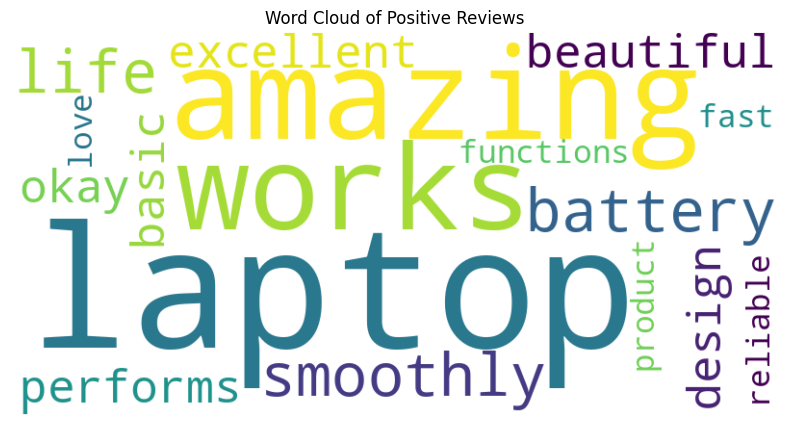

In [7]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This laptop is amazing and works very smoothly.",
    "The battery life is excellent and the design is beautiful.",
    "The product is terrible and extremely disappointing.",
    "The delivery was slow and the packaging was damaged.",
    "The laptop is okay and performs its basic functions.",
    "I love this product because it is fast and reliable."
]

positive_reviews = []

print("SENTIMENT ANALYSIS\n")

for i, review in enumerate(reviews, start=1):
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review {i}: {review}")
    print(f"Polarity: {polarity:.2f}")
    print(f"Subjectivity: {subjectivity:.2f}")
    print(f"Sentiment: {sentiment}\n")

    if sentiment == "Positive":
        positive_reviews.append(review)

if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews available for the word cloud.")

In [6]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Artificial intelligence is transforming modern technology.
Machine learning allows computers to learn from data.
Deep learning uses neural networks to solve complex problems.
Technology helps people communicate and share information.
Students use computers to learn programming and mathematics.
Artificial intelligence can improve healthcare and education.
Data science helps researchers discover useful patterns.
Python is a popular language for machine learning.
Neural networks learn patterns from training examples.
Computers can generate text using language models.
Artificial intelligence continues to develop rapidly.
Machine learning applications are used in many industries.
Students can build intelligent systems using Python.
Technology creates opportunities for innovation and creativity.
Learning artificial intelligence requires practice and patience.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

input_sequences = []

for line in text.lower().strip().split("\n"):
    line = line.strip()

    if line:
        sequence = tokenizer.texts_to_sequences([line])[0]

        for i in range(2, len(sequence) + 1):
            input_sequences.append(sequence[:i])

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=16,
        input_length=X.shape[1]
    ),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.fit(
    X,
    y,
    epochs=100,
    verbose=0
)

print("Model training completed!")

def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        sequence = tokenizer.texts_to_sequences([seed_text])[0]

        sequence = pad_sequences(
            [sequence],
            maxlen=X.shape[1],
            padding="pre"
        )

        predictions = model.predict(sequence, verbose=0)[0]

        predicted_id = int(np.argmax(predictions))

        if predicted_id == 0:
            break

        output_word = tokenizer.index_word.get(predicted_id)

        if output_word is None:
            break

        seed_text += " " + output_word

    return seed_text

seed_word = "machine"

print("\nGenerated Text:\n")

for i in range(3):
    print(generate_text(seed_word, next_words=10) + ".")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model training completed!

Generated Text:

machine learning learning to to learn from data problems problems problems.
machine learning learning to to learn from data problems problems problems.
machine learning learning to to learn from data problems problems problems.
